In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(observables, filename):
    return (uproot.open(filename)["MatchedTree"]).arrays(observables, library='pd')

In [4]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [5]:
import math
def weighted_avg_and_std(values, weights):
    """
    Return the weighted average and standard deviation.

    values, weights -- Numpy ndarrays with the same shape.
    """
    average = np.average(values, weights=weights)
    # Fast and numerically precise:
    variance = np.average((values-average)**2, weights=weights)
    return (average, math.sqrt(variance))

# No track matching

## 2023 embedding

In [8]:
observables = ['pt','q','m','rg','zg','mg','w']
observabless = ['pts']#,'qs','ms','rgs','zgs','mgs']
inputFiles = ['/vast/palmer/home.grace/ys668/output/run12/all050124.root']
df1 = applyCut(getData(observables+observabless, inputFiles[0]), 'pt>0 and pts>0 and w<5e-9')

In [9]:
df1.eval('dpt_pt = (pts-pt)/pt', inplace=True)
df1.eval('dpt = pts-pt', inplace=True)

In [11]:
df_match_pts_array = [ df1[(df1.pts>20) & (df1.pts<25)],\
                       df1[(df1.pts>25) & (df1.pts<30)],\
                       df1[(df1.pts>30) & (df1.pts<40)],\
                       df1[(df1.pts>40) & (df1.pts<60)]]

0.03638633592260422 0.2544278855476416
detector-level pT bin: 0


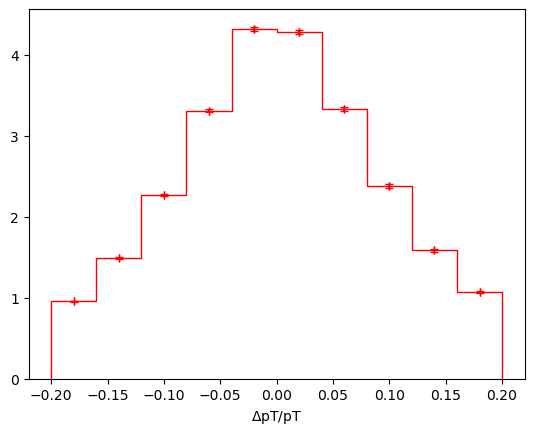

0.044755651078654334 0.2710315218586039
detector-level pT bin: 1


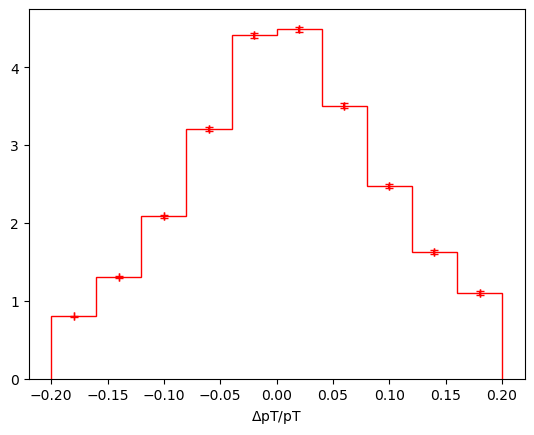

0.06677447486401236 0.32288840488298515
detector-level pT bin: 2


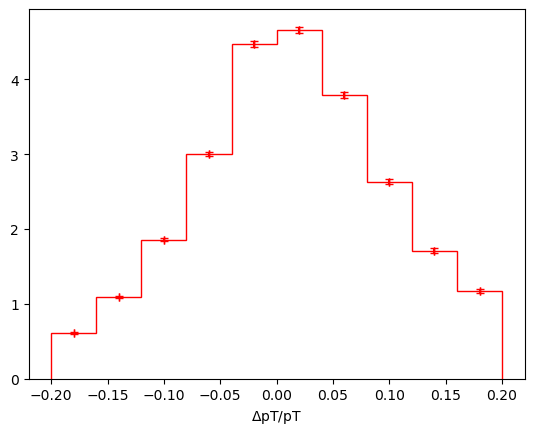

0.13303254555846414 0.4419723506963168
detector-level pT bin: 3


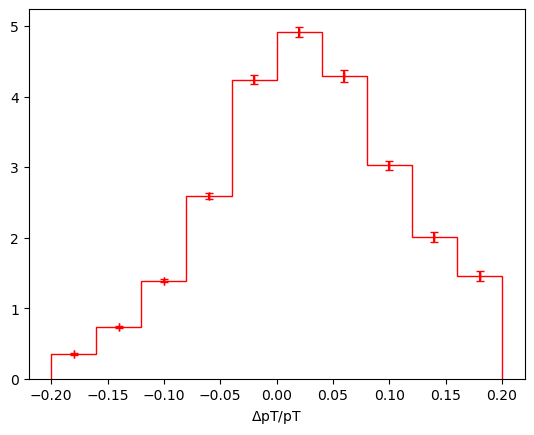

In [19]:
dpt_pt_array = []
sigma_dpt_pt_array = []
for i in range(0,4):
    df_temp = df_match_pts_array[i]
    dpt_pt, sigma_dpt_pt = weighted_avg_and_std(df_temp['dpt_pt'], df_temp['w'])
    print(dpt_pt, sigma_dpt_pt)
    dpt_pt_array.append(dpt_pt)
    sigma_dpt_pt_array.append(sigma_dpt_pt)
    y_temp, yerr_temp, x = calc_hist(df_temp['dpt_pt'], weights=df_temp['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    print('detector-level pT bin:', i)
    plt.hist(df_temp['dpt_pt'], weights=df_temp['w'], color='r', histtype='step', range=(-0.2,0.2), density=True)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp/sum(y_temp), xerr=0, yerr=25*yerr_temp/sum(y_temp), color='r',ls='none',capsize=3)
    plt.xlabel('$\Delta$pT/pT')
    plt.ylim(bottom=0)
    plt.show()

In [16]:
err_on_mean = []
for j in range(0,4):
    df = df_match_pts_array[j]
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['dpt_pt'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean.append(err2)

In [18]:
sigma_dpt_pt_array

[0.2544278855476416,
 0.2710315218586039,
 0.32288840488298515,
 0.4419723506963168]

(-0.6, 0.6)

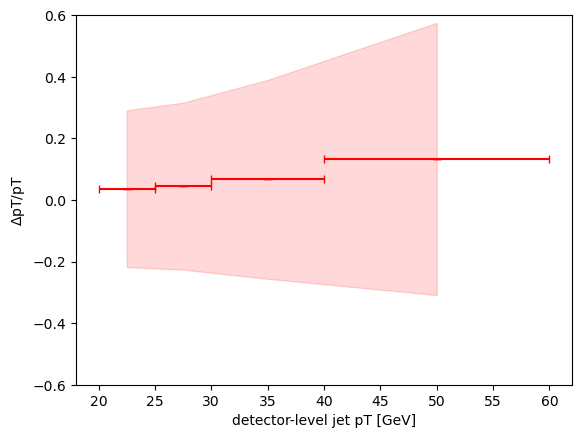

In [28]:
plt.errorbar([22.5, 27.5, 35, 50], dpt_pt_array, xerr=[2.5, 2.5, 5, 10], yerr=err_on_mean, color='r', ls='none', capsize=3)
plt.fill_between([22.5, 27.5, 35, 50], np.array(dpt_pt_array)-np.array(sigma_dpt_pt_array), np.array(dpt_pt_array)+np.array(sigma_dpt_pt_array), color='r', alpha=0.15)
plt.xlabel('detector-level jet pT [GeV]')
plt.ylabel('$\Delta$pT/pT')
plt.ylim(-0.6,0.6)

In [39]:
df_match_pt_array = [ df1[(df1.pt>20) & (df1.pt<25)],\
                       df1[(df1.pt>25) & (df1.pt<30)],\
                       df1[(df1.pt>30) & (df1.pt<40)],\
                       df1[(df1.pt>40) & (df1.pt<60)]]

-0.07980398053970493 0.1215917056111264
detector-level pT bin: 0


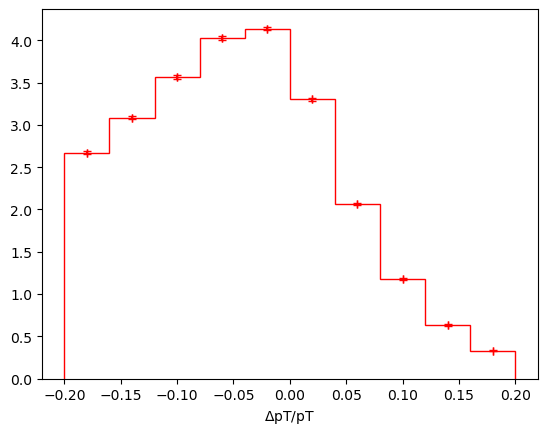

-0.1188128395057987 0.1454509382387907
detector-level pT bin: 1


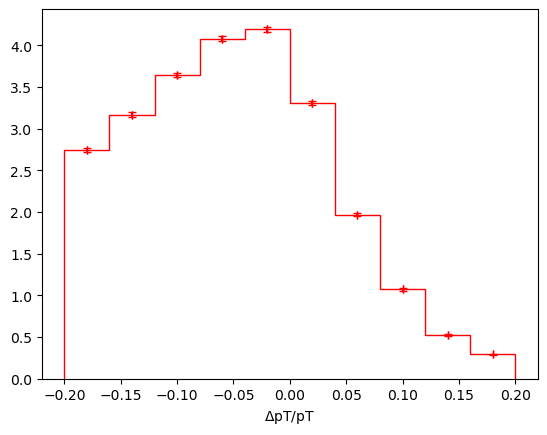

-0.14640896473764173 0.1636961031731216
detector-level pT bin: 2


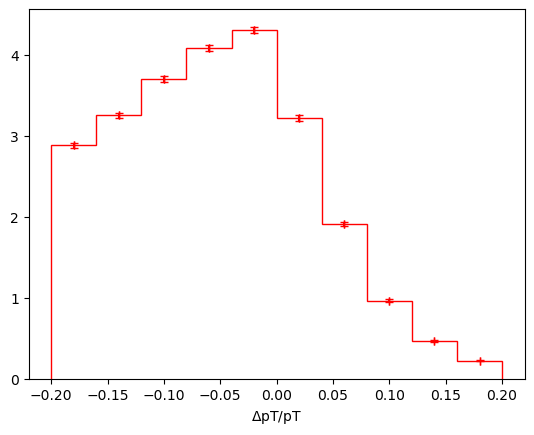

-0.18730753072532785 0.18170367049077205
detector-level pT bin: 3


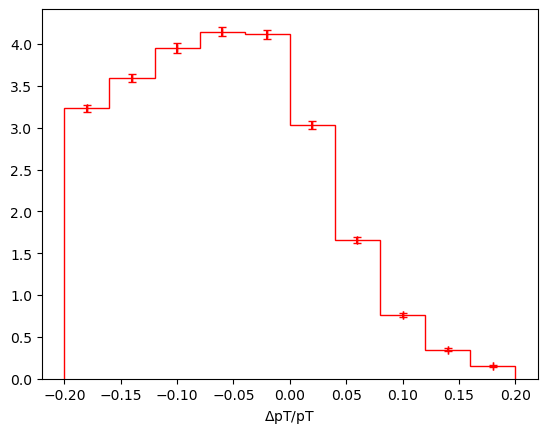

In [40]:
dpt_pt_array = []
sigma_dpt_pt_array = []
for i in range(0,4):
    df_temp = df_match_pt_array[i]
    dpt_pt, sigma_dpt_pt = weighted_avg_and_std(df_temp['dpt_pt'], df_temp['w'])
    print(dpt_pt, sigma_dpt_pt)
    dpt_pt_array.append(dpt_pt)
    sigma_dpt_pt_array.append(sigma_dpt_pt)
    y_temp, yerr_temp, x = calc_hist(df_temp['dpt_pt'], weights=df_temp['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    print('detector-level pT bin:', i)
    plt.hist(df_temp['dpt_pt'], weights=df_temp['w'], color='r', histtype='step', range=(-0.2,0.2), density=True)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp/sum(y_temp), xerr=0, yerr=25*yerr_temp/sum(y_temp), color='r',ls='none',capsize=3)
    plt.xlabel('$\Delta$pT/pT')
    plt.ylim(bottom=0)
    plt.show()

In [41]:
err_on_mean = []
for j in range(0,4):
    df = df_match_pt_array[j]
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['dpt_pt'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean.append(err2)

In [42]:
sigma_dpt_pt_array

[0.1215917056111264,
 0.1454509382387907,
 0.1636961031731216,
 0.18170367049077205]

(-0.6, 0.6)

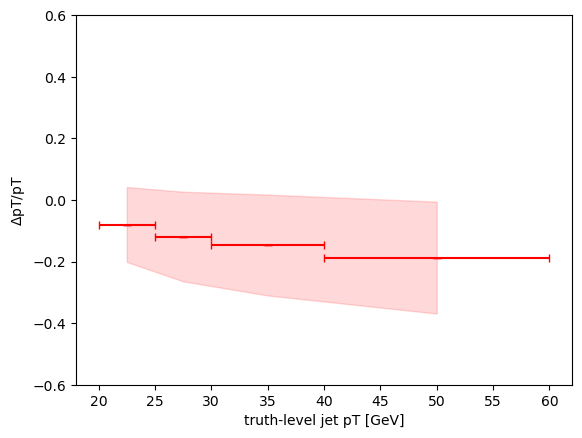

In [43]:
plt.errorbar([22.5, 27.5, 35, 50], dpt_pt_array, xerr=[2.5, 2.5, 5, 10], yerr=err_on_mean, color='r', ls='none', capsize=3)
plt.fill_between([22.5, 27.5, 35, 50], np.array(dpt_pt_array)-np.array(sigma_dpt_pt_array), np.array(dpt_pt_array)+np.array(sigma_dpt_pt_array), color='r', alpha=0.15)
plt.xlabel('truth-level jet pT [GeV]')
plt.ylabel('$\Delta$pT/pT')
plt.ylim(-0.6,0.6)

## 2015 embedding

In [30]:
observables1 = ['pt','b','m','n','w','reject','pt1','pt2','qlead','qsublead','y1','y2','phi1','phi2','nef']
observabless1 = ['pts','bs','ms','ns','ws','rejects','pt1s','pt2s','qleads','qsubleads','y1s','y2s','phi1s','phi2s', 'nefs']
df = applyCut(getData(observables1+observabless1, '/gpfs/gibbs/project/havener/ys668/rc/all0615_final.root'),\
              'pts>15 and reject<=0 and rejects<=0')

In [31]:
df.eval('dpt_pt = (pts-pt)/pt', inplace=True)
df.eval('dpt = pts-pt', inplace=True)

In [32]:
df_match_pts_array = [ df[(df.pts>20) & (df.pts<25)],\
                       df[(df.pts>25) & (df.pts<30)],\
                       df[(df.pts>30) & (df.pts<40)],\
                       df[(df.pts>40) & (df.pts<60)]]

-0.04086357723789545 0.6033468912161954
detector-level pT bin: 0


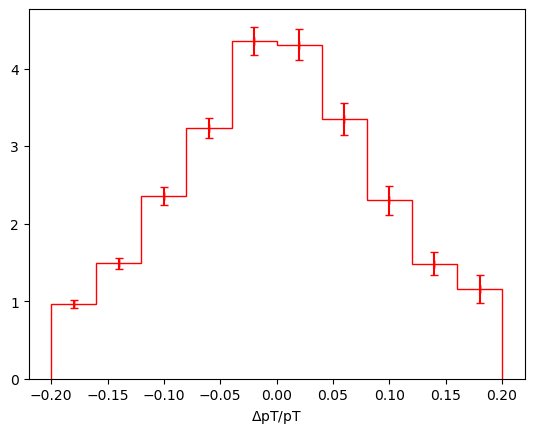

-0.07985809901358497 0.6953185370798153
detector-level pT bin: 1


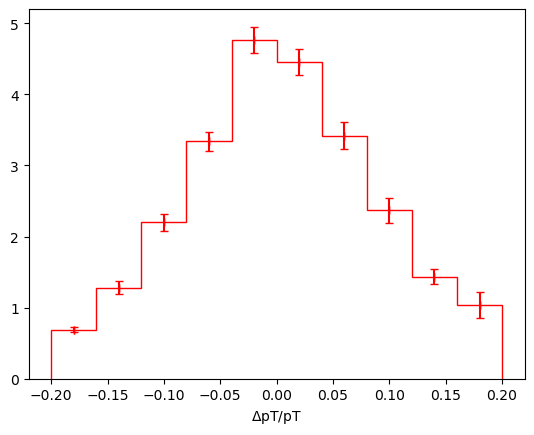

-0.04075774064575983 0.7754230530789973
detector-level pT bin: 2


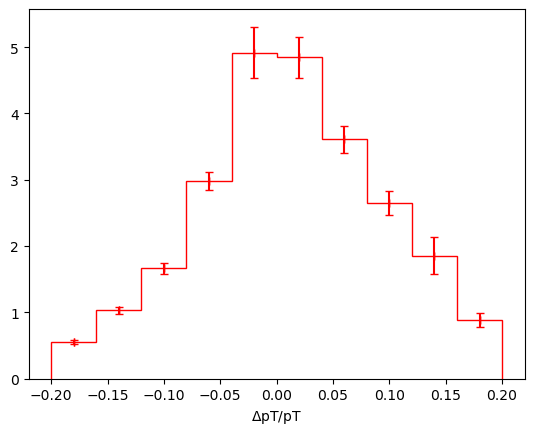

0.1302706808125727 0.5253594990995661
detector-level pT bin: 3


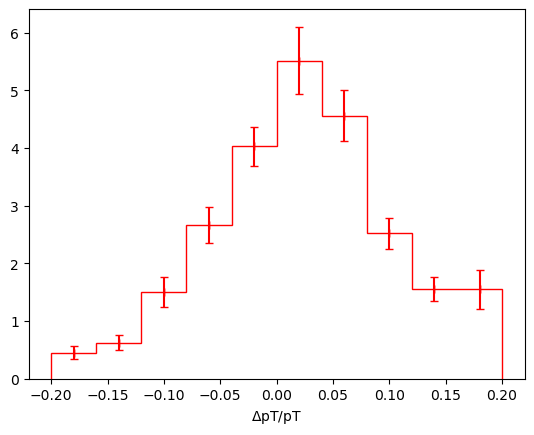

In [33]:
dpt_pt_array = []
sigma_dpt_pt_array = []
for i in range(0,4):
    df_temp = df_match_pts_array[i]
    dpt_pt, sigma_dpt_pt = weighted_avg_and_std(df_temp['dpt_pt'], df_temp['w'])
    print(dpt_pt, sigma_dpt_pt)
    dpt_pt_array.append(dpt_pt)
    sigma_dpt_pt_array.append(sigma_dpt_pt)
    y_temp, yerr_temp, x = calc_hist(df_temp['dpt_pt'], weights=df_temp['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    print('detector-level pT bin:', i)
    plt.hist(df_temp['dpt_pt'], weights=df_temp['w'], color='r', histtype='step', range=(-0.2,0.2), density=True)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp/sum(y_temp), xerr=0, yerr=25*yerr_temp/sum(y_temp), color='r',ls='none',capsize=3)
    plt.xlabel('$\Delta$pT/pT')
    plt.ylim(bottom=0)
    plt.show()

In [34]:
err_on_mean = []
for j in range(0,4):
    df = df_match_pts_array[j]
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['dpt_pt'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean.append(err2)

In [35]:
sigma_dpt_pt_array

[0.6033468912161954,
 0.6953185370798153,
 0.7754230530789973,
 0.5253594990995661]

(-0.6, 0.6)

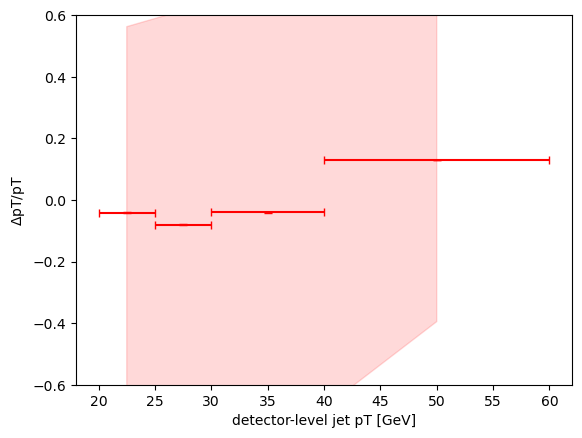

In [38]:
plt.errorbar([22.5, 27.5, 35, 50], dpt_pt_array, xerr=[2.5, 2.5, 5, 10], yerr=err_on_mean, color='r', ls='none', capsize=3)
plt.fill_between([22.5, 27.5, 35, 50], np.array(dpt_pt_array)-np.array(sigma_dpt_pt_array), np.array(dpt_pt_array)+np.array(sigma_dpt_pt_array), color='r', alpha=0.15)
plt.xlabel('detector-level jet pT [GeV]')
plt.ylabel('$\Delta$pT/pT')
plt.ylim(-0.6,0.6)

# With leading charged tracks

## 2023 embedding

In [9]:
observables1 = ['pt','b','w','qlead','qsublead','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','ws','qleads','qsubleads','y1s','y2s','phi1s','phi2s']
df = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all050124_rc.root'),\
              'pt>0 and pts>15 and bs!=-9 and bs!=0')

In [10]:
distance1 = []
distance2 = []
for i in range(0,df.shape[0]):
    phi1small = min(df.iloc[i]['phi1'], df.iloc[i]['phi1s'])
    phi1large = max(df.iloc[i]['phi1'], df.iloc[i]['phi1s'])
    phi2small = min(df.iloc[i]['phi2'], df.iloc[i]['phi2s'])
    phi2large = max(df.iloc[i]['phi2'], df.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df.iloc[i]['phi1'], df.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df.iloc[i]['y1']-df.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df.iloc[i]['y2']-df.iloc[i]['y2s'])**2))
df['distance1'] = distance1
df['distance2'] = distance2

In [11]:
df_match = applyCut(df, 'pt>5 and b!=-9 and b!=0 and distance1 < 0.02 and distance2 < 0.02')

In [12]:
df_match.eval('dpt_pt = (pts-pt)/pt', inplace=True)
df_match.eval('dpt = pts-pt', inplace=True)

In [23]:
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)] ]

detector-level pT bin: 0


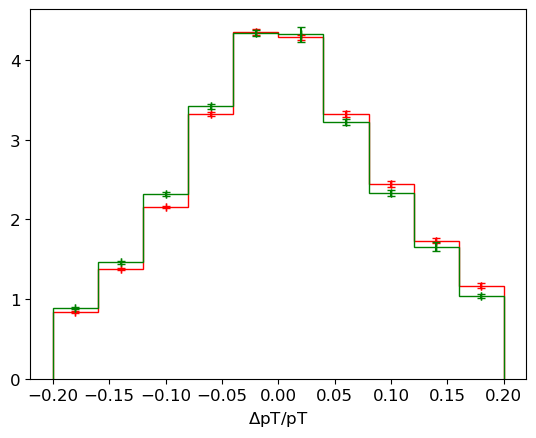

detector-level pT bin: 1


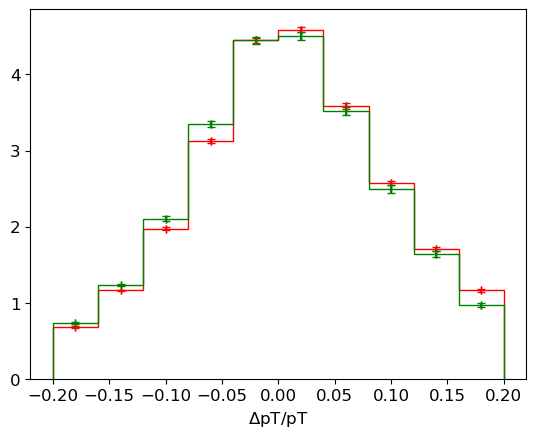

detector-level pT bin: 2


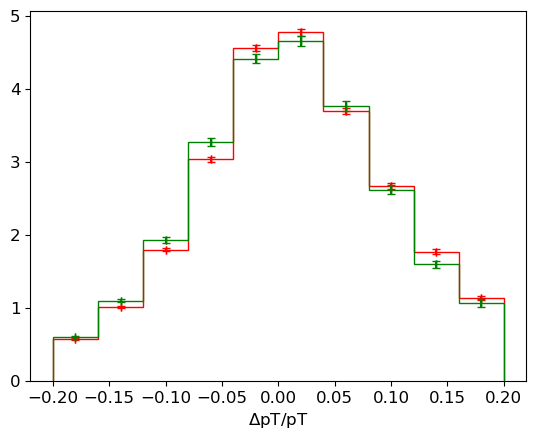

detector-level pT bin: 3


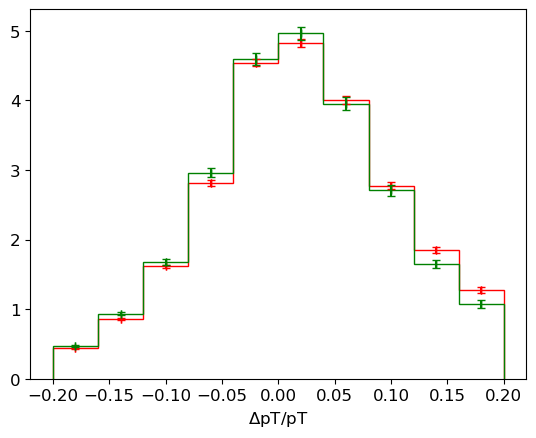

In [45]:
dpt_pt_array_os = []
sigma_dpt_pt_array_os = []
dpt_pt_array_ss = []
sigma_dpt_pt_array_ss = []
for i in range(0,4):
    df_temp_os = applyCut(df_match_pts_array[i], 'bs==-1')
    df_temp_ss = applyCut(df_match_pts_array[i], 'bs==1')
    dpt_pt_os, sigma_dpt_pt_os = weighted_avg_and_std(df_temp_os['dpt_pt'], df_temp_os['w'])
    dpt_pt_ss, sigma_dpt_pt_ss = weighted_avg_and_std(df_temp_ss['dpt_pt'], df_temp_ss['w'])
    dpt_pt_array_os.append(dpt_pt_os)
    sigma_dpt_pt_array_os.append(sigma_dpt_pt_os)
    dpt_pt_array_ss.append(dpt_pt_ss)
    sigma_dpt_pt_array_ss.append(sigma_dpt_pt_ss)
    y_temp_os, yerr_temp_os, x = calc_hist(df_temp_os['dpt_pt'], weights=df_temp_os['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    y_temp_ss, yerr_temp_ss, x = calc_hist(df_temp_ss['dpt_pt'], weights=df_temp_ss['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    print('detector-level pT bin:', i)
    plt.hist(df_temp_os['dpt_pt'], weights=df_temp_os['w'], color='r', histtype='step', range=(-0.2,0.2), density=True)
    plt.hist(df_temp_ss['dpt_pt'], weights=df_temp_ss['w'], color='g', histtype='step', range=(-0.2,0.2), density=True)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_os/sum(y_temp_os), xerr=0, yerr=25*yerr_temp_os/sum(y_temp_os), color='r',ls='none',capsize=3)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_ss/sum(y_temp_ss), xerr=0, yerr=25*yerr_temp_ss/sum(y_temp_ss), color='g',ls='none',capsize=3)
    plt.xlabel('$\Delta$pT/pT')
    plt.ylim(bottom=0)
    plt.show()

In [46]:
err_on_mean_os = []
for j in range(0,4):
    df = applyCut(df_match_pts_array[j], 'b==-1')
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['dpt_pt'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean_os.append(err2)

In [47]:
err_on_mean_ss = []
for j in range(0,4):
    df = applyCut(df_match_pts_array[j], 'b==1')
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['dpt_pt'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean_ss.append(err2)

In [27]:
plt.rcParams['font.size'] = 12

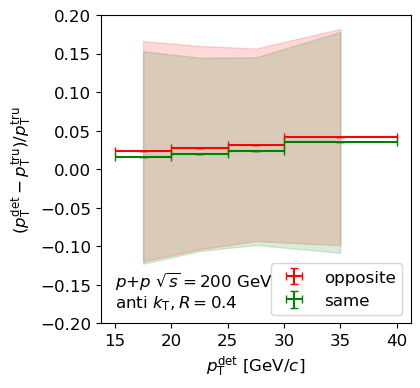

In [48]:
figure = plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_os, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean_os, color='r', label='opposite', ls='none', capsize=3)
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_ss, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean_ss, color='g', label='same', ls='none', capsize=3)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(dpt_pt_array_os)-np.array(sigma_dpt_pt_array_os), np.array(dpt_pt_array_os)+np.array(sigma_dpt_pt_array_os), color='r', alpha=0.15)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(dpt_pt_array_ss)-np.array(sigma_dpt_pt_array_ss), np.array(dpt_pt_array_ss)+np.array(sigma_dpt_pt_array_ss), color='g', alpha=0.15)
plt.xlabel('$p_{\mathrm{T}}^{\mathrm{det}}$ [GeV$/c$]')
plt.ylabel(r'$(p_{\mathrm{T}}^{\mathrm{det}}-p_{\mathrm{T}}^{\mathrm{tru}})/p_{\mathrm{T}}^{\mathrm{tru}}$')
plt.text(15, -0.18, '$p$+$p$ $\sqrt{s}=200$ GeV\nanti $k_{\mathrm{T}}, R=0.4$')
plt.ylim(-0.2,0.2)
plt.legend(loc='lower right')

In [18]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)] ]

truth-level pT bin: 0


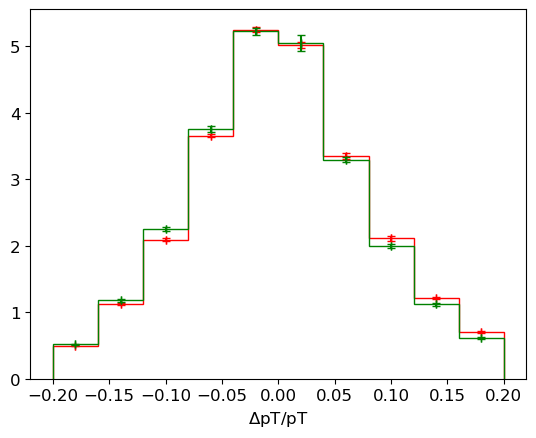

truth-level pT bin: 1


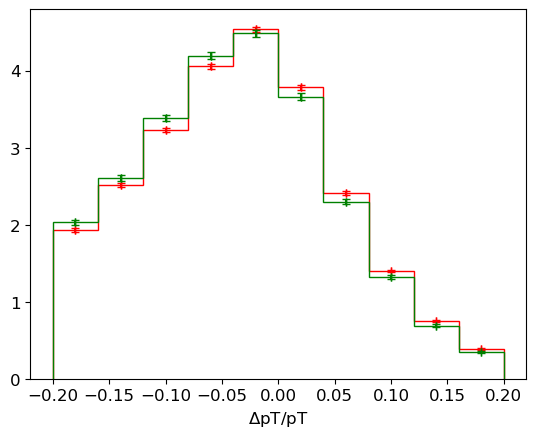

truth-level pT bin: 2


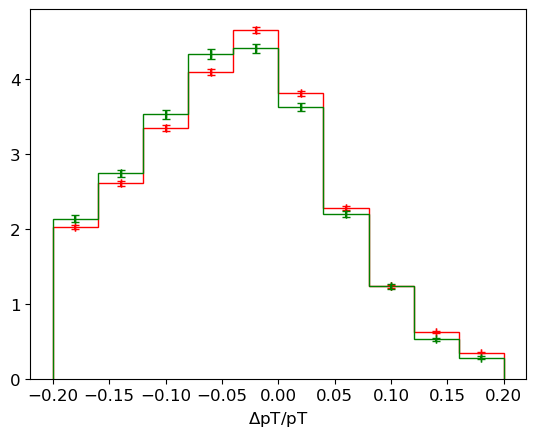

truth-level pT bin: 3


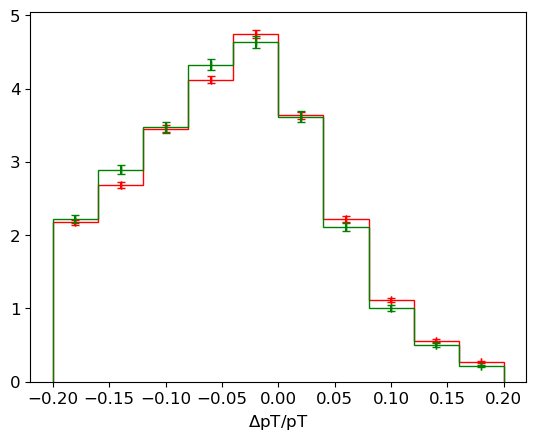

In [36]:
dpt_pt_array_os = []
sigma_dpt_pt_array_os = []
dpt_pt_array_ss = []
sigma_dpt_pt_array_ss = []
for i in range(0,4):
    df_temp_os = applyCut(df_match_pt_array[i], 'bs==-1')
    df_temp_ss = applyCut(df_match_pt_array[i], 'bs==1')
    dpt_pt_os, sigma_dpt_pt_os = weighted_avg_and_std(df_temp_os['dpt_pt'], df_temp_os['w'])
    dpt_pt_ss, sigma_dpt_pt_ss = weighted_avg_and_std(df_temp_ss['dpt_pt'], df_temp_ss['w'])
    dpt_pt_array_os.append(dpt_pt_os)
    sigma_dpt_pt_array_os.append(sigma_dpt_pt_os)
    dpt_pt_array_ss.append(dpt_pt_ss)
    sigma_dpt_pt_array_ss.append(sigma_dpt_pt_ss)
    y_temp_os, yerr_temp_os, x = calc_hist(df_temp_os['dpt_pt'], weights=df_temp_os['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    y_temp_ss, yerr_temp_ss, x = calc_hist(df_temp_ss['dpt_pt'], weights=df_temp_ss['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    print('truth-level pT bin:', i)
    plt.hist(df_temp_os['dpt_pt'], weights=df_temp_os['w'], color='r', histtype='step', range=(-0.2,0.2), density=True)
    plt.hist(df_temp_ss['dpt_pt'], weights=df_temp_ss['w'], color='g', histtype='step', range=(-0.2,0.2), density=True)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_os/sum(y_temp_os), xerr=0, yerr=25*yerr_temp_os/sum(y_temp_os), color='r',ls='none',capsize=3)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_ss/sum(y_temp_ss), xerr=0, yerr=25*yerr_temp_ss/sum(y_temp_ss), color='g',ls='none',capsize=3)
    plt.xlabel('$\Delta$pT/pT')
    plt.ylim(bottom=0)
    plt.show()

In [37]:
err_on_mean_os = []
for j in range(0,4):
    df = applyCut(df_match_pt_array[j], 'b==-1')
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['dpt_pt'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean_os.append(err2)

In [38]:
err_on_mean_ss = []
for j in range(0,4):
    df = applyCut(df_match_pt_array[j], 'b==1')
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['dpt_pt'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean_ss.append(err2)

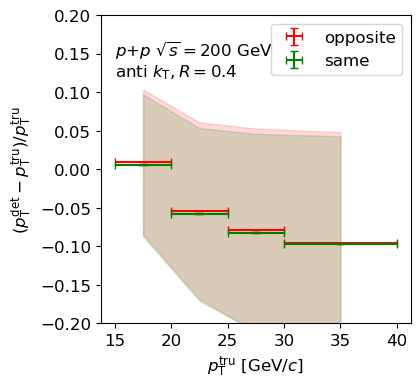

In [41]:
fig = plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_os, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean_os, color='r', label='opposite', ls='none', capsize=3)
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_ss, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean_ss, color='g', label='same', ls='none', capsize=3)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(dpt_pt_array_os)-np.array(sigma_dpt_pt_array_os), np.array(dpt_pt_array_os)+np.array(sigma_dpt_pt_array_os), color='r', alpha=0.15)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(dpt_pt_array_ss)-np.array(sigma_dpt_pt_array_ss), np.array(dpt_pt_array_ss)+np.array(sigma_dpt_pt_array_ss), color='g', alpha=0.15)
plt.xlabel('$p_{\mathrm{T}}^{\mathrm{tru}}$ [GeV$/c$]')
plt.ylabel(r'$(p_{\mathrm{T}}^{\mathrm{det}}-p_{\mathrm{T}}^{\mathrm{tru}})/p_{\mathrm{T}}^{\mathrm{tru}}$')
plt.text(15, 0.12, '$p$+$p$ $\sqrt{s}=200$ GeV\nanti $k_{\mathrm{T}}, R=0.4$')
plt.ylim(-0.2,0.2)
plt.legend()

## 2015 embedding

In [8]:
observables1 = ['pt','b','m','n','w','reject','pt1','pt2','qlead','qsublead','y1','y2','phi1','phi2','nef']
observabless1 = ['pts','bs','ms','ns','ws','rejects','pt1s','pt2s','qleads','qsubleads','y1s','y2s','phi1s','phi2s', 'nefs']
df = applyCut(getData(observables1+observabless1, '/gpfs/gibbs/project/havener/ys668/rc/all0615_final.root', "MatchedTree"),\
              'pts>15 and bs!=-9 and bs!=0 and reject<=0 and rejects<=0')

In [9]:
distance1 = []
distance2 = []
for i in range(0,df.shape[0]):
    phi1small = min(df.iloc[i]['phi1'], df.iloc[i]['phi1s'])
    phi1large = max(df.iloc[i]['phi1'], df.iloc[i]['phi1s'])
    phi2small = min(df.iloc[i]['phi2'], df.iloc[i]['phi2s'])
    phi2large = max(df.iloc[i]['phi2'], df.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df.iloc[i]['phi1'], df.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df.iloc[i]['y1']-df.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df.iloc[i]['y2']-df.iloc[i]['y2s'])**2))
df['distance1'] = distance1
df['distance2'] = distance2

In [10]:
df_match = applyCut(df, 'pt>5 and b!=-9 and b!=0 and distance1 < 0.02 and distance2 < 0.02')

In [11]:
df_match = applyCut(df_match, 'not (pts>25 and w>4e-9)') # removes one high weight jet

In [12]:
df_match.eval('dpt_pt = (pts-pt)/pt', inplace=True)
df_match.eval('dpt = pts-pt', inplace=True)
df_match.eval('dpt1 = pt1s-pt1', inplace=True)
df_match.eval('dpt2 = pt2s-pt2', inplace=True)
df_match.eval('dpt_dihadron = dpt1+dpt2', inplace=True)
df_match.eval('spt_dihadron = pt1+pt2', inplace=True)

In [13]:
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)] ]

detector-level pT bin: 0


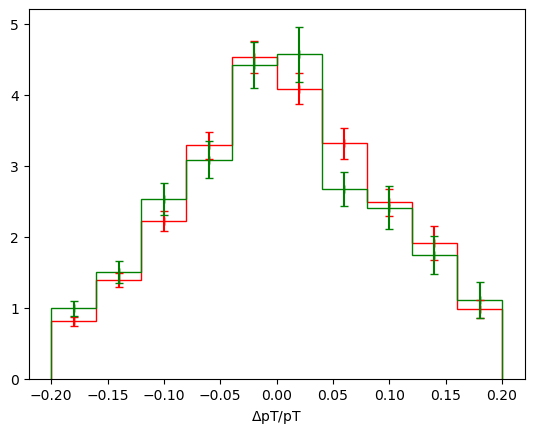

detector-level pT bin: 1


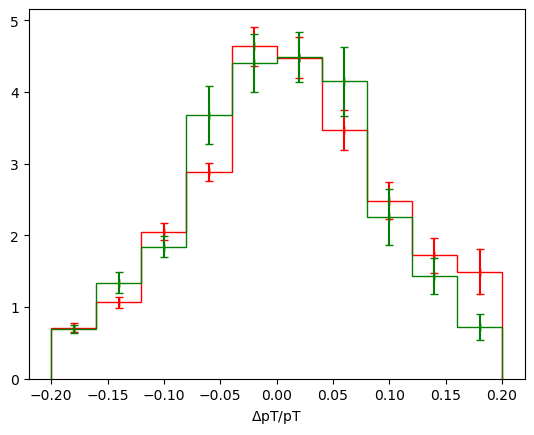

detector-level pT bin: 2


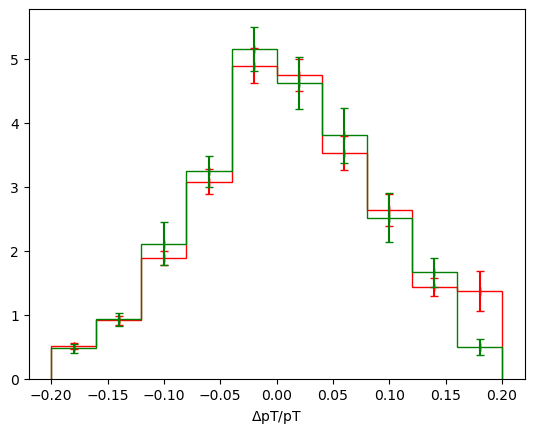

detector-level pT bin: 3


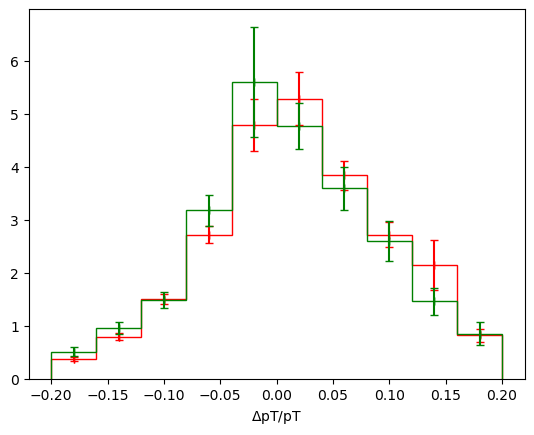

In [20]:
dpt_pt_array_os = []
sigma_dpt_pt_array_os = []
dpt_pt_array_ss = []
sigma_dpt_pt_array_ss = []
for i in range(0,4):
    df_temp_os = applyCut(df_match_pts_array[i], 'bs==-1')
    df_temp_ss = applyCut(df_match_pts_array[i], 'bs==1')
    dpt_pt_os, sigma_dpt_pt_os = weighted_avg_and_std(df_temp_os['dpt_pt'], df_temp_os['w'])
    dpt_pt_ss, sigma_dpt_pt_ss = weighted_avg_and_std(df_temp_ss['dpt_pt'], df_temp_ss['w'])
    dpt_pt_array_os.append(dpt_pt_os)
    sigma_dpt_pt_array_os.append(sigma_dpt_pt_os)
    dpt_pt_array_ss.append(dpt_pt_ss)
    sigma_dpt_pt_array_ss.append(sigma_dpt_pt_ss)
    y_temp_os, yerr_temp_os, x = calc_hist(df_temp_os['dpt_pt'], weights=df_temp_os['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    y_temp_ss, yerr_temp_ss, x = calc_hist(df_temp_ss['dpt_pt'], weights=df_temp_ss['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    print('detector-level pT bin:', i)
    plt.hist(df_temp_os['dpt_pt'], weights=df_temp_os['w'], color='r', histtype='step', range=(-0.2,0.2), density=True)
    plt.hist(df_temp_ss['dpt_pt'], weights=df_temp_ss['w'], color='g', histtype='step', range=(-0.2,0.2), density=True)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_os/sum(y_temp_os), xerr=0, yerr=25*yerr_temp_os/sum(y_temp_os), color='r',ls='none',capsize=3)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_ss/sum(y_temp_ss), xerr=0, yerr=25*yerr_temp_ss/sum(y_temp_ss), color='g',ls='none',capsize=3)
    plt.xlabel('$\Delta$pT/pT')
    plt.ylim(bottom=0)
    plt.show()

In [16]:
err_on_mean_os = []
for j in range(0,4):
    df = applyCut(df_match_pts_array[j], 'b==-1')
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['dpt_pt'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean_os.append(err2)

In [17]:
err_on_mean_ss = []
for j in range(0,4):
    df = applyCut(df_match_pts_array[j], 'b==1')
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['dpt_pt'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean_ss.append(err2)

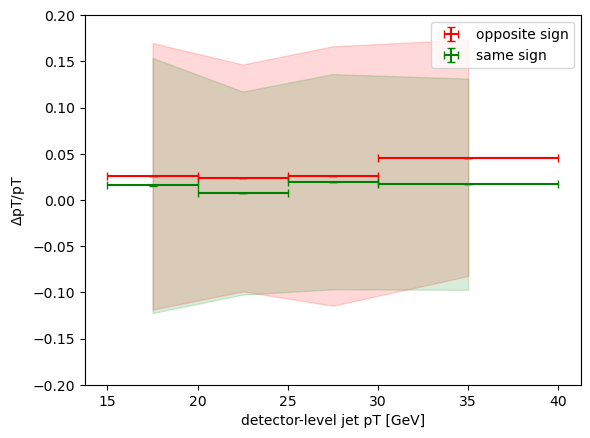

In [21]:
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_os, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean_os, color='r', label='opposite sign', ls='none', capsize=3)
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_ss, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean_ss, color='g', label='same sign', ls='none', capsize=3)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(dpt_pt_array_os)-np.array(sigma_dpt_pt_array_os), np.array(dpt_pt_array_os)+np.array(sigma_dpt_pt_array_os), color='r', alpha=0.15)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(dpt_pt_array_ss)-np.array(sigma_dpt_pt_array_ss), np.array(dpt_pt_array_ss)+np.array(sigma_dpt_pt_array_ss), color='g', alpha=0.15)
plt.xlabel('detector-level jet pT [GeV]')
plt.ylabel('$\Delta$pT/pT')
plt.ylim(-0.2,0.2)
plt.legend()

In [22]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)] ]

truth-level pT bin: 0


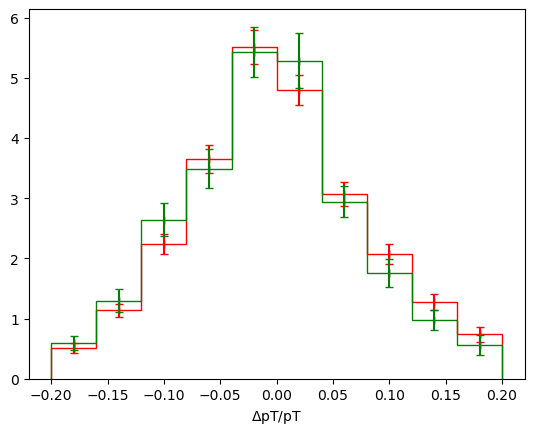

truth-level pT bin: 1


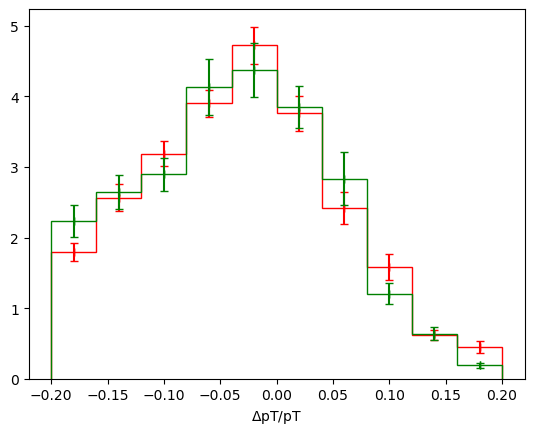

truth-level pT bin: 2


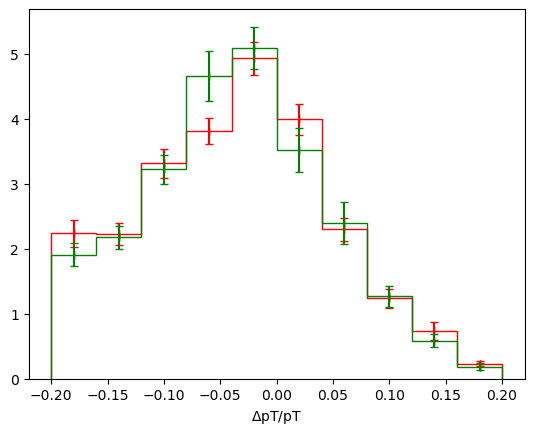

truth-level pT bin: 3


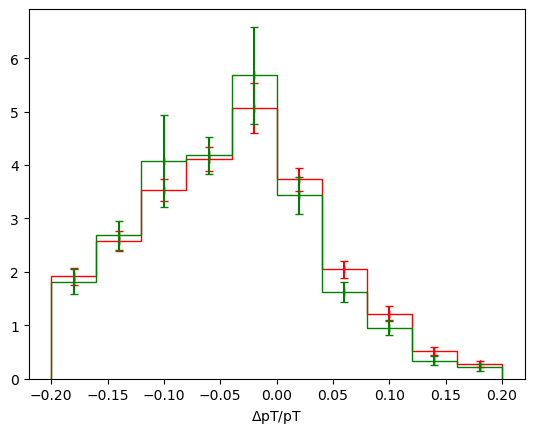

In [23]:
dpt_pt_array_os = []
sigma_dpt_pt_array_os = []
dpt_pt_array_ss = []
sigma_dpt_pt_array_ss = []
for i in range(0,4):
    df_temp_os = applyCut(df_match_pt_array[i], 'bs==-1')
    df_temp_ss = applyCut(df_match_pt_array[i], 'bs==1')
    dpt_pt_os, sigma_dpt_pt_os = weighted_avg_and_std(df_temp_os['dpt_pt'], df_temp_os['w'])
    dpt_pt_ss, sigma_dpt_pt_ss = weighted_avg_and_std(df_temp_ss['dpt_pt'], df_temp_ss['w'])
    dpt_pt_array_os.append(dpt_pt_os)
    sigma_dpt_pt_array_os.append(sigma_dpt_pt_os)
    dpt_pt_array_ss.append(dpt_pt_ss)
    sigma_dpt_pt_array_ss.append(sigma_dpt_pt_ss)
    y_temp_os, yerr_temp_os, x = calc_hist(df_temp_os['dpt_pt'], weights=df_temp_os['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    y_temp_ss, yerr_temp_ss, x = calc_hist(df_temp_ss['dpt_pt'], weights=df_temp_ss['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    print('truth-level pT bin:', i)
    plt.hist(df_temp_os['dpt_pt'], weights=df_temp_os['w'], color='r', histtype='step', range=(-0.2,0.2), density=True)
    plt.hist(df_temp_ss['dpt_pt'], weights=df_temp_ss['w'], color='g', histtype='step', range=(-0.2,0.2), density=True)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_os/sum(y_temp_os), xerr=0, yerr=25*yerr_temp_os/sum(y_temp_os), color='r',ls='none',capsize=3)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_ss/sum(y_temp_ss), xerr=0, yerr=25*yerr_temp_ss/sum(y_temp_ss), color='g',ls='none',capsize=3)
    plt.xlabel('$\Delta$pT/pT')
    plt.ylim(bottom=0)
    plt.show()

In [24]:
err_on_mean_os = []
for j in range(0,4):
    df = applyCut(df_match_pt_array[j], 'b==-1')
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['dpt_pt'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean_os.append(err2)

In [25]:
err_on_mean_ss = []
for j in range(0,4):
    df = applyCut(df_match_pt_array[j], 'b==1')
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['dpt_pt'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean_ss.append(err2)

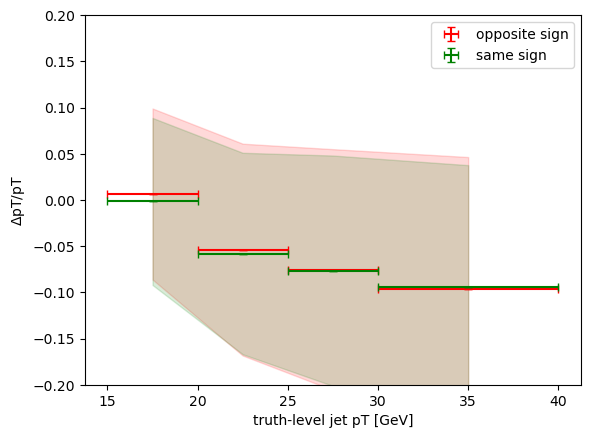

In [26]:
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_os, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean_os, color='r', label='opposite sign', ls='none', capsize=3)
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_ss, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean_ss, color='g', label='same sign', ls='none', capsize=3)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(dpt_pt_array_os)-np.array(sigma_dpt_pt_array_os), np.array(dpt_pt_array_os)+np.array(sigma_dpt_pt_array_os), color='r', alpha=0.15)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(dpt_pt_array_ss)-np.array(sigma_dpt_pt_array_ss), np.array(dpt_pt_array_ss)+np.array(sigma_dpt_pt_array_ss), color='g', alpha=0.15)
plt.xlabel('truth-level jet pT [GeV]')
plt.ylabel('$\Delta$pT/pT')
plt.ylim(-0.2,0.2)
plt.legend()